<a href="https://colab.research.google.com/github/belwalparth/Machine-learning_Credit_fraud_prediction/blob/main/Machine_Learning_Credit_Fraud_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip -q install kaggle
from google.colab import files
import os, shutil, zipfile

if not os.path.exists('train.csv'):
    files.upload()  # Choose kaggle.json
    os.makedirs('/root/.kaggle', exist_ok=True)
    shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)
    !kaggle competitions download -c playground-series-s6e11
    with zipfile.ZipFile('playground-series-s6e11.zip') as z:
        z.extractall('.')
print('Dataset ready!')

Saving kaggle.json to kaggle (1).json
100% 29.5M/29.5M [00:00<00:00, 178MB/s]

Dataset ready!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score, precision_recall_curve, f1_score

raw = pd.read_csv('train.csv')
print('Shape:', raw.shape)
print('Fraud counts:')
print(raw['is_fraud'].value_counts())
print('Fraud percentage:', round(raw['is_fraud'].mean()*100, 2))
display(raw.head())

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Shape: (699960, 26)
Fraud counts:
is_fraud
0.0    688271
1.0     11689
Name: count, dtype: int64
Fraud percentage: 1.67


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [4]:
X = raw.select_dtypes(include='number').drop(columns=['id', 'is_fraud'], errors='ignore')
y = raw['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=42
)
print('Features:', list(X.columns))
print('Train:', len(X_fit), 'Validation:', len(X_val), 'Test:', len(X_test))


Features: ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']
Train: 447974 Validation: 111994 Test: 139992


In [5]:
models = {
    'Logistic Regression': make_pipeline(
        SimpleImputer(strategy='median'), StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    'Random Forest': make_pipeline(
        SimpleImputer(strategy='median'),
        RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
    )
}

for name, model in models.items():
    model.fit(X_fit, y_fit)
    predictions = model.predict(X_val)
    print('\n', name, '— validation results')
    print(classification_report(y_val, predictions, zero_division=0))


 Logistic Regression — validation results
              precision    recall  f1-score   support

         0.0       0.98      1.00      0.99    110124
         1.0       0.64      0.10      0.17      1870

    accuracy                           0.98    111994
   macro avg       0.81      0.55      0.58    111994
weighted avg       0.98      0.98      0.98    111994


 Random Forest — validation results
              precision    recall  f1-score   support

         0.0       0.98      1.00      0.99    110124
         1.0       0.88      0.03      0.05      1870

    accuracy                           0.98    111994
   macro avg       0.93      0.51      0.52    111994
weighted avg       0.98      0.98      0.98    111994



In [6]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_scores = cross_val_score(models['Logistic Regression'], X_train, y_train,
                            cv=cv, scoring='f1', n_jobs=1)
print('F1 in each fold:', cv_scores)
print('Mean F1:', round(cv_scores.mean(), 3))

F1 in each fold: [0.15654596 0.16875522 0.17324138]
Mean F1: 0.166


In [7]:
results = []
for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    ap = average_precision_score(y_val, probabilities)
    best_t, best_f1 = 0.5, -1
    for t in np.arange(0.05, 0.96, 0.05):
        score = f1_score(y_val, probabilities >= t, zero_division=0)
        if score > best_f1:
            best_t, best_f1 = float(t), score
    results.append({'Model': name, 'Threshold': best_t,
                    'Validation F1': best_f1, 'Validation AP': ap})

comparison = pd.DataFrame(results).sort_values('Validation F1', ascending=False)
display(comparison)
selected = comparison.iloc[0]
print('Selected:', selected['Model'], 'at threshold', selected['Threshold'])

,Model,Threshold,Validation F1,Validation AP
0,Logistic Regression,0.15,0.318099,0.264134
1,Random Forest,0.10,0.315953,0.269564


Selected: Logistic Regression at threshold 0.15000000000000002


In [8]:
name = selected['Model']
threshold = float(selected['Threshold'])
final_model = models[name]
final_model.fit(X_train, y_train)
probabilities = final_model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= threshold).astype(int)

print('FINAL MODEL:', name)
print('THRESHOLD:', threshold)
print(classification_report(y_test, predictions, zero_division=0))
print('Confusion matrix:\n', confusion_matrix(y_test, predictions))
print('Average Precision:', round(average_precision_score(y_test, probabilities), 4))

FINAL MODEL: Logistic Regression
THRESHOLD: 0.15000000000000002
              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99    137654
         1.0       0.30      0.31      0.31      2338

    accuracy                           0.98    139992
   macro avg       0.64      0.65      0.65    139992
weighted avg       0.98      0.98      0.98    139992

Confusion matrix:
 [[135945   1709]
 [  1606    732]]
Average Precision: 0.2408


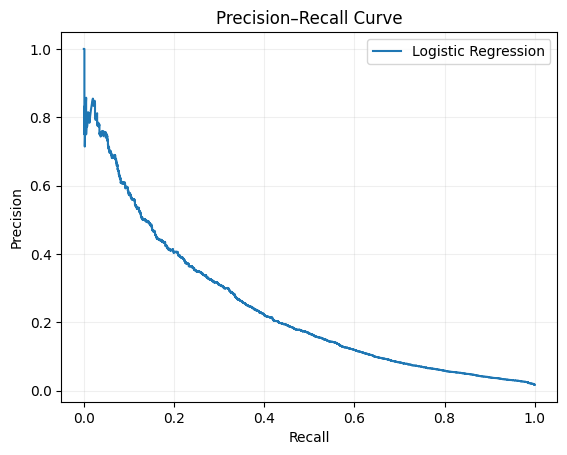

In [9]:
precision, recall, _ = precision_recall_curve(y_test, probabilities)
plt.plot(recall, precision, label=name)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve')
plt.legend()
plt.grid(alpha=0.2)
plt.savefig('precision_recall_curve.png', bbox_inches='tight')
plt.show()

In [10]:
from sklearn.metrics import precision_score, recall_score
with open('results.txt', 'w') as f:
    f.write(f'Model: {name}\nThreshold: {threshold:.2f}\n')
    f.write(f'Precision: {precision_score(y_test, predictions, zero_division=0):.4f}\n')
    f.write(f'Recall: {recall_score(y_test, predictions, zero_division=0):.4f}\n')
    f.write(f'F1: {f1_score(y_test, predictions, zero_division=0):.4f}\n')
    f.write(f'Average Precision: {average_precision_score(y_test, probabilities):.4f}\n')
print(open('results.txt').read())
files.download('results.txt')
files.download('precision_recall_curve.png')

Model: Logistic Regression
Threshold: 0.15
Precision: 0.2999
Recall: 0.3131
F1: 0.3063
Average Precision: 0.2408



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>